In [1]:
from uq_physicell.model_analysis import calculate_qoi_from_db_file
import warnings
warnings.filterwarnings('ignore')  # Suppress all warnings for cleaner output

db_file = 'ex9_Simulations.db'
qoi_funcs = {
    'walltime':    lambda mcds: mcds.get_runtime() 
}

# Calculate the QoIs based on the qoi_funcs
df_qois = calculate_qoi_from_db_file(db_file, qoi_funcs, n_jobs=10)
last_time = df_qois['time'].max()
df_last_time = df_qois[df_qois['time'] == last_time]
display(df_last_time)

,SampleID,time,ReplicateID,walltime
150,0,7200.0,0,570.770921
151,0,7200.0,1,567.596118
152,0,7200.0,2,580.920372
153,0,7200.0,3,560.877927
154,0,7200.0,4,566.085813
...,...,...,...,...
29755,191,7200.0,0,391.820722
29756,191,7200.0,1,387.361137
29757,191,7200.0,2,368.979060
29758,191,7200.0,3,349.871237


In [3]:
from uq_physicell.model_analysis import load_samples
import pandas as pd

# Normalize the QOIs by the nominal case (row with all rules activated)
dic_parameters = load_samples(db_file)
df_samples_desc = pd.DataFrame.from_dict(dic_parameters, orient='index')
df_last_time = df_last_time.merge(df_samples_desc, left_on='SampleID', right_index=True)
display(df_last_time)

,SampleID,time,ReplicateID,walltime,apoptosis_rate,cell_cycle_entry
150,0,7200.0,0,570.770921,0.000060,1350.571931
151,0,7200.0,1,567.596118,0.000060,1350.571931
152,0,7200.0,2,580.920372,0.000060,1350.571931
153,0,7200.0,3,560.877927,0.000060,1350.571931
154,0,7200.0,4,566.085813,0.000060,1350.571931
...,...,...,...,...,...,...
29755,191,7200.0,0,391.820722,0.000063,1330.475319
29756,191,7200.0,1,387.361137,0.000063,1330.475319
29757,191,7200.0,2,368.979060,0.000063,1330.475319
29758,191,7200.0,3,349.871237,0.000063,1330.475319


Median walltime (min): 8.990894050000001 minutes
95th Percentile walltime (min): 45.48453226583323 minutes


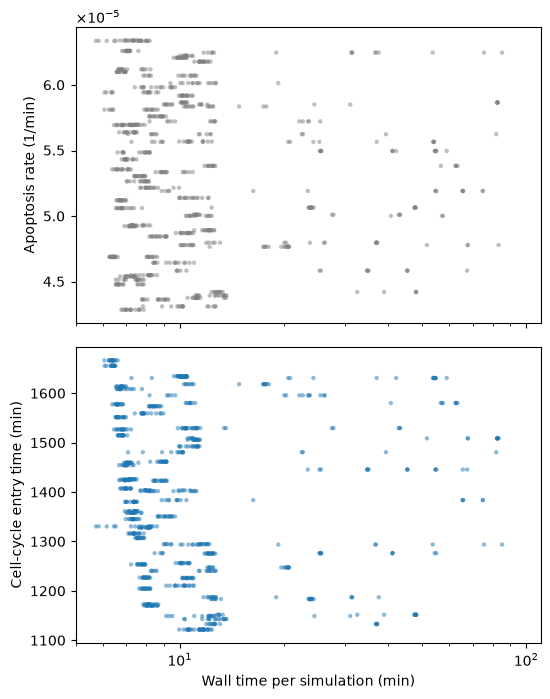

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
# Convert walltime from seconds to minutes for better readability
df_last_time['walltime (min)'] = df_last_time['walltime'] / 60

fig, ax = plt.subplots(2, 1, figsize=(6, 8), sharex=True,gridspec_kw={'height_ratios': [6, 6], 'hspace': 0.08})
sns.scatterplot(data=df_last_time, y='apoptosis_rate', x='walltime (min)', ax=ax[0], s=10, alpha=0.5, edgecolor='none', color='gray')
ax[0].set(ylabel='Apoptosis rate (1/min)')
ax[0].ticklabel_format(style='sci', axis='y', scilimits=(0, 0), useMathText=True)
sns.scatterplot(data=df_last_time, y='cell_cycle_entry', x='walltime (min)',ax=ax[1], s=10, alpha=0.5, edgecolor='none')
ax[1].set(xlabel='Wall time per simulation (min)', ylabel='Cell-cycle entry time (min)', xscale='log', xlim =(5, 110))
plt.savefig('ex9_walltime.svg', format='svg')

print(f"Median walltime (min): {df_last_time['walltime (min)'].median()} minutes")
print(f"95th Percentile walltime (min): {df_last_time['walltime (min)'].quantile(0.95)} minutes")